# SAIDS 521 Assignment 3

At the time I'm completing this assingment, it is mid-November and my fantasy football team has already lost hope for the year. Given that, I thought it would be fun to explore some trends in historical fantasy football performances to help me prepare better for next season. I have some hunches on trends I want to capitalize on next season, so we'll be checking if they have any statistical validity.

## Data Pull

For my data, I did some research and found the nflreadpy library, which allows me to pull weekly fantasy data for any given season.

https://nflreadpy.nflverse.com/

The license to this data can be found here.

https://nflreadpy.nflverse.com/LICENSE/

This is the first time I've used a local instance of Python on this computer, so I had to use AI to help with my local SSL configuration. This process has been documented in my AI log.

In [1]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "nflreadpy"])


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


CompletedProcess(args=['/usr/local/bin/python3', '-m', 'pip', 'install', 'nflreadpy'], returncode=0)

In [2]:
subprocess.run([sys.executable, "-m", "pip", "install", "--upgrade", "certifi"])


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


CompletedProcess(args=['/usr/local/bin/python3', '-m', 'pip', 'install', '--upgrade', 'certifi'], returncode=0)

In [3]:
import ssl, certifi
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())

In [4]:
import nflreadpy as nfl
import pandas as pd

raw_data = nfl.load_player_stats([2025])
weekly_df = pd.DataFrame(raw_data.to_dict(as_series=False))
weekly_df.head()

,player_id,player_name,player_display_name,position,position_group,headshot_url,season,week,season_type,game_id,...,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards,fantasy_points,fantasy_points_ppr
0,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_PIT_NYJ,...,0,0,0,0,0,0,0,0,25.66,25.66
1,00-0023853,M.Prater,Matt Prater,K,SPEC,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_BAL_BUF,...,0,0,0,0,0,0,0,0,0.00,0.00
2,00-0025565,N.Folk,Nick Folk,K,SPEC,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_PIT_NYJ,...,0,0,0,0,0,0,0,0,0.00,0.00
3,00-0026158,J.Flacco,Joe Flacco,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_CIN_CLE,...,0,0,0,0,0,0,0,0,12.20,12.20
4,00-0026190,C.Campbell,Calais Campbell,DE,DL,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_ARI_NO,...,0,0,0,0,0,0,0,0,0.00,0.00


Before we get into cleaning, I'll save a raw version of the data for reference.

In [5]:
weekly_df.to_csv("data/raw_weekly_data.csv", index = False)

## Data Cleaning and Feature Engineering

In most fantasy leagues, including mine, only Quarterbacks, Runningbacks, Wide Receivers, and TEs are included. Let's remove all other positions from this data.

In [91]:
weekly_df = weekly_df[weekly_df['position'].isin(['QB', 'RB', 'WR', 'TE'])]
weekly_df['position'].unique()

<StringArray>
['QB', 'WR', 'TE', 'RB']
Length: 4, dtype: str

Additionally, I am only interested in a subset of these columns. I can drop the rest.

In [92]:
for col in weekly_df.columns:
    print(col)

player_id
player_name
player_display_name
position
position_group
headshot_url
season
week
season_type
game_id
team
opponent_team
completions
attempts
passing_yards
passing_tds
passing_interceptions
sacks_suffered
sack_yards_lost
sack_fumbles
sack_fumbles_lost
passing_air_yards
passing_yards_after_catch
passing_first_downs
passing_epa
passing_cpoe
passing_2pt_conversions
pacr
passing_10
passing_16
passing_20
passing_40
carries
rushing_yards
rushing_tds
rushing_fumbles
rushing_fumbles_lost
rushing_first_downs
rushing_epa
rushing_2pt_conversions
rushing_10
rushing_12
rushing_20
rushing_40
receptions
targets
receiving_yards
receiving_tds
receiving_fumbles
receiving_fumbles_lost
receiving_air_yards
receiving_yards_after_catch
receiving_first_downs
receiving_epa
receiving_2pt_conversions
receiving_10
receiving_16
receiving_20
receiving_40
racr
target_share
air_yards_share
wopr
special_teams_tds
def_tackles_solo
def_tackles_with_assist
def_tackle_assists
def_tackles_for_loss
def_tackles_for_

In [93]:
filtered_df = weekly_df[['player_id', 'player_name', 'headshot_url', 'position', 'week', 'team', #Categories
                      'passing_yards', 'passing_tds', 'passing_interceptions', #QB Stats
                      'rushing_yards', 'rushing_tds', 'receiving_yards', 'receiving_tds', 'receptions', #Non QB stats
                      'fantasy_points_ppr' #Response Variable
]]

In [94]:
filtered_df.info()

<class 'pandas.DataFrame'>
Index: 6321 entries, 0 to 19420
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   player_id              6321 non-null   str    
 1   player_name            6321 non-null   str    
 2   headshot_url           6318 non-null   str    
 3   position               6321 non-null   str    
 4   week                   6321 non-null   int64  
 5   team                   6321 non-null   str    
 6   passing_yards          6321 non-null   int64  
 7   passing_tds            6321 non-null   int64  
 8   passing_interceptions  6321 non-null   int64  
 9   rushing_yards          6321 non-null   int64  
 10  rushing_tds            6321 non-null   int64  
 11  receiving_yards        6321 non-null   int64  
 12  receiving_tds          6321 non-null   int64  
 13  receptions             6321 non-null   int64  
 14  fantasy_points_ppr     6321 non-null   float64
dtypes: float64(1), int6

This dataframe seems to be clean with no missing values. Only headshots have missing values, which is fine as I am only keeping that column as a potential fun tooltip for my vizualizations.

In [95]:
filtered_df.describe()

,week,passing_yards,passing_tds,passing_interceptions,rushing_yards,rushing_tds,receiving_yards,receiving_tds,receptions,fantasy_points_ppr
count,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000
mean,9.983547,20.337605,0.135105,0.064230,10.510679,0.082582,20.217212,0.133523,1.843854,7.418171
std,5.597472,67.131617,0.547234,0.321666,24.129108,0.333966,28.470923,0.383461,2.168856,7.905154
min,1.000000,-2.000000,0.000000,0.000000,-14.000000,0.000000,-10.000000,0.000000,0.000000,-3.060000
25%,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.300000
50%,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,0.000000,1.000000,4.900000
75%,15.000000,0.000000,0.000000,0.000000,7.000000,0.000000,30.000000,0.000000,3.000000,11.320000
max,22.000000,470.000000,5.000000,4.000000,244.000000,4.000000,225.000000,3.000000,16.000000,55.400000


Looking at this summary, I can see that the data goes until Week 22 of the season. This means it includes playoff football, which standard fantasy leagues (including mine) do not. Lets filter down the data to end at Week 17.

In [96]:
filtered_df = filtered_df[filtered_df['week'] <= 17]

The different position groups do not accumulate points at the same rate, lets normalize points by position group to account for this. This normalized scoring is what I'll use when charts span across position groups.

In [97]:
position_group = filtered_df.groupby('position')['fantasy_points_ppr']

filtered_df['normalized_ppr'] = position_group.transform(lambda x: (x - x.mean()) / x.std())
filtered_df.head()

,player_id,player_name,headshot_url,position,week,team,passing_yards,passing_tds,passing_interceptions,rushing_yards,rushing_tds,receiving_yards,receiving_tds,receptions,fantasy_points_ppr,normalized_ppr
0,00-0023459,A.Rodgers,https://static.www.nfl.com/image/upload/f_auto...,QB,1,PIT,244,4,0,-1,0,0,0,0,25.66,1.283362
3,00-0026158,J.Flacco,https://static.www.nfl.com/image/upload/f_auto...,QB,1,CLE,290,1,2,6,0,0,0,0,12.20,-0.145101
5,00-0026498,M.Stafford,https://static.www.nfl.com/image/upload/f_auto...,QB,1,LA,245,1,0,-2,0,0,0,0,13.60,0.003476
15,00-0029263,R.Wilson,https://static.www.nfl.com/image/upload/f_auto...,QB,1,NYG,168,0,0,44,0,0,0,0,11.12,-0.259718
23,00-0030035,A.Thielen,https://static.www.nfl.com/image/upload/f_auto...,WR,1,MIN,0,0,0,0,0,0,0,0,2.00,-0.643389


I also want to potentially view this data on a divisional level. I have a theory that cold weather divisions have different behaviors than warm weather divisions as the months get colder. Lets map teams to divisions to create this field.

**Note:** Generative AI was used to create this mapping to avoid manual hardcoding. This was included in AI log.

In [98]:
filtered_df['team'].unique()

<StringArray>
['PIT', 'CLE',  'LA', 'NYG', 'MIN', 'WAS', 'LAC',  'KC', 'BAL',  'LV',  'NO',
  'TB',  'NE', 'TEN', 'DET', 'MIA', 'DAL', 'IND', 'JAX',  'SF', 'CIN', 'ARI',
 'ATL', 'SEA', 'CAR', 'HOU', 'DEN', 'NYJ', 'PHI', 'CHI', 'BUF',  'GB']
Length: 32, dtype: str

In [99]:
nfl_division_map = {
    # AFC East
    'BUF': 'AFC East',
    'MIA': 'AFC East',
    'NE':  'AFC East',
    'NYJ': 'AFC East',
    
    # AFC North
    'BAL': 'AFC North',
    'CIN': 'AFC North',
    'CLE': 'AFC North',
    'PIT': 'AFC North',
    
    # AFC South
    'HOU': 'AFC South',
    'IND': 'AFC South',
    'JAX': 'AFC South',
    'TEN': 'AFC South',
    
    # AFC West
    'DEN': 'AFC West',
    'KC':  'AFC West',
    'LV':  'AFC West',
    'LAC': 'AFC West',
    
    # NFC East
    'DAL': 'NFC East',
    'NYG': 'NFC East',
    'PHI': 'NFC East',
    'WAS': 'NFC East',
    
    # NFC North
    'CHI': 'NFC North',
    'DET': 'NFC North',
    'GB':  'NFC North',
    'MIN': 'NFC North',
    
    # NFC South
    'ATL': 'NFC South',
    'CAR': 'NFC South',
    'NO':  'NFC South',
    'TB':  'NFC South',
    
    # NFC West
    'ARI': 'NFC West',
    'LA':  'NFC West',  # Los Angeles Rams
    'SF':  'NFC West',
    'SEA': 'NFC West'
}

filtered_df['division'] = filtered_df['team'].map(nfl_division_map)

Now that I have data that I want to begin vizualizing, I'll save this cleaned version along with the original raw data.

In [100]:
filtered_df.to_csv("data/clean_weekly_data.csv", index = False)

## Vizualizations

Below I'll create 4 vizualizations that will become the foundation for my overall dashboard.

### Lolipop Chart

At my job, we regularly vizual client interactions with lolipop charts showing the timeline of contacts. I think this would be a cool way to vizualize which player is having the best week overall after setting the desired filters.

In particular, I want to see if there is a difference in top overall fantasy players and top standardized players. To acheive better results next year, I want to select players with the most marginal value over their positional peers.

In [101]:
%pip install plotly


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [102]:
%pip install --upgrade nbformat


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [103]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [104]:
fantasy_data = filtered_df.copy()

In [105]:
idx_max_raw = fantasy_data.groupby('week')['fantasy_points_ppr'].idxmax()
df_top_raw = fantasy_data.loc[idx_max_raw].sort_values('week').reset_index(drop=True)

idx_max_norm = fantasy_data.groupby('week')['normalized_ppr'].idxmax()
df_top_norm = fantasy_data.loc[idx_max_norm].sort_values('week').reset_index(drop=True)

# 3. Define a consistent color mapping for unique positions
position_color_map = {"RB": '#d62728', 'QB': '#1f77b4', 'WR': '#ff7f0e', 'TE': '#2ca02c'}
fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=("Weekly Top PPR Scorer", "Weekly Top Normalized Scorer"),
    vertical_spacing=0.3
)

In [106]:
def create_hovertemplate(val_name, is_norm=False):
    fmt = ":.2f" if is_norm else ""
    return (
        "<b>Name:</b> %{customdata[0]}<br>"
        f"<b>{val_name}:</b> %{{y{fmt}}}<br>"
        "<b>Week:</b> %{x}<br>"
        "<extra></extra>"
    )

In [107]:
def add_position_lollipops(row_idx, target_df, val_col, val_label, is_norm=False):
    # Group by position so each position generates a single cleaner legend entry
    for pos in target_df['position'].unique():
        pos_df = target_df[target_df['position'] == pos]
        color = position_color_map.get(pos, '#333333')
        
        # Draw the gray vertical stem lines for this position's points
        for _, row in pos_df.iterrows():
            fig.add_trace(
                go.Scatter(
                    x=[row['week'], row['week']],
                    y=[0, row[val_col]],
                    mode='lines',
                    line=dict(color='lightgray', width=2),
                    showlegend=False,
                    hoverinfo='skip'
                ),
                row=row_idx, col=1
            )
        
        # Prepare custom data (Name, Position, Image_URL)
        custom_data = list(zip(pos_df['player_name'], pos_df['position'], pos_df['headshot_url']))
        
        # Add lollipop marker heads
        fig.add_trace(
            go.Scatter(
                x=pos_df['week'],
                y=pos_df[val_col],
                mode='markers',
                marker=dict(size=14, color=color),
                name=pos,                       # Category name for the legend
                legendgroup=pos,                # Links same positions across subplots
                showlegend=(row_idx == 1),      # Only show legend once in the top plot to avoid duplicates
                customdata=custom_data,
                hovertemplate=create_hovertemplate(val_label, is_norm=is_norm)
            ),
            row=row_idx, col=1
        )

# --- TOP PLOT: Raw Values ---
add_position_lollipops(1, df_top_raw, 'fantasy_points_ppr', 'PPR Fantasy Points', is_norm=False)

# --- BOTTOM PLOT: Normalized Values ---
add_position_lollipops(2, df_top_norm, 'normalized_ppr', 'Normalized Fantasy Points', is_norm=True)

# 5. Layout Styling & Legend Placement
fig.update_layout(
    height=800,
    template="simple_white",
    title_text="<b>Weekly Top PPR scorers</b>",
    legend=dict(
        title="<b>Position</b>",
        x=1.02, 
        y=0.5,
        xanchor="left",
        yanchor="middle"
    ),
    hoverlabel=dict(
        bgcolor="white",
        font_size=12,
        font_family="Arial"
    )
)

# Axis configurations
fig.update_xaxes(title_text="Week", row=1, col=1)
fig.update_yaxes(title_text="PPR Fantasy Points", row=1, col=1, rangemode="tozero")

fig.update_xaxes(title_text="Week", row=2, col=1)
fig.update_yaxes(title_text="Normalized Fantasy Points", row=2, col=1, rangemode="tozero")

fig.show()

This is chart is really insightful, while Quarterbacks occasionally scored the most, they never had the highest relative value compared to their peers. Wide recievers on the other hand seemed to benifit more from the normalized scoring system.

In future years, I may avoid drafting quarterbacks early as it seems they do not stand out in comparison to their peers at the same rate as other positions. I'll be particulary interested in the top wide recievers and tight ends.

**Note:** AI was used in the creation of this chart. These prompts, along with what they got incorrect have been included in the AI log.

### Scatterplot Matrices:

The weekly high scorers was an interesting chart overall, but we can get more granular on how input variables are interacting with eachother. I am interested to see these relationships plotted out, particulary with our response variables.

In [59]:
%pip install seaborn

  Obtaining dependency information for seaborn from https://files.pythonhosted.org/packages/83/11/00d3c3dfc25ad54e731d91449895a79e4bf2384dc3ac01809010ba88f6d5/seaborn-0.13.2-py3-none-any.whl.metadata
  Obtaining dependency information for matplotlib!=3.6.1,>=3.4 from https://files.pythonhosted.org/packages/a6/c4/7f5f3601ee69baf072c0c7d3ce60c03e0618621c5a56c34a62a460e29d11/matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 847.2 kB/s eta 0:00:00 0:00:01
  Obtaining dependency information for contourpy>=1.0.1 from https://files.pythonhosted.org/packages/dd/f5/c5bf67522d49a2222f3154fe46879451d26f0e35ece41770758a64ea78cb/contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata
  Obtaining dependency information for cycler>=0.10 from https://files.pythonhosted.org/packages/e7/05/c19819d5e3d95294a6f5947fb9b9629efb316b96de511b418c53d245aae6/cycler-0.12.1-py3-none-any.whl.metadata
  Obtaining dependency information for fontt

In [65]:
fantasy_data.columns[fantasy_data.columns.duplicated()]

Index([], dtype='str')

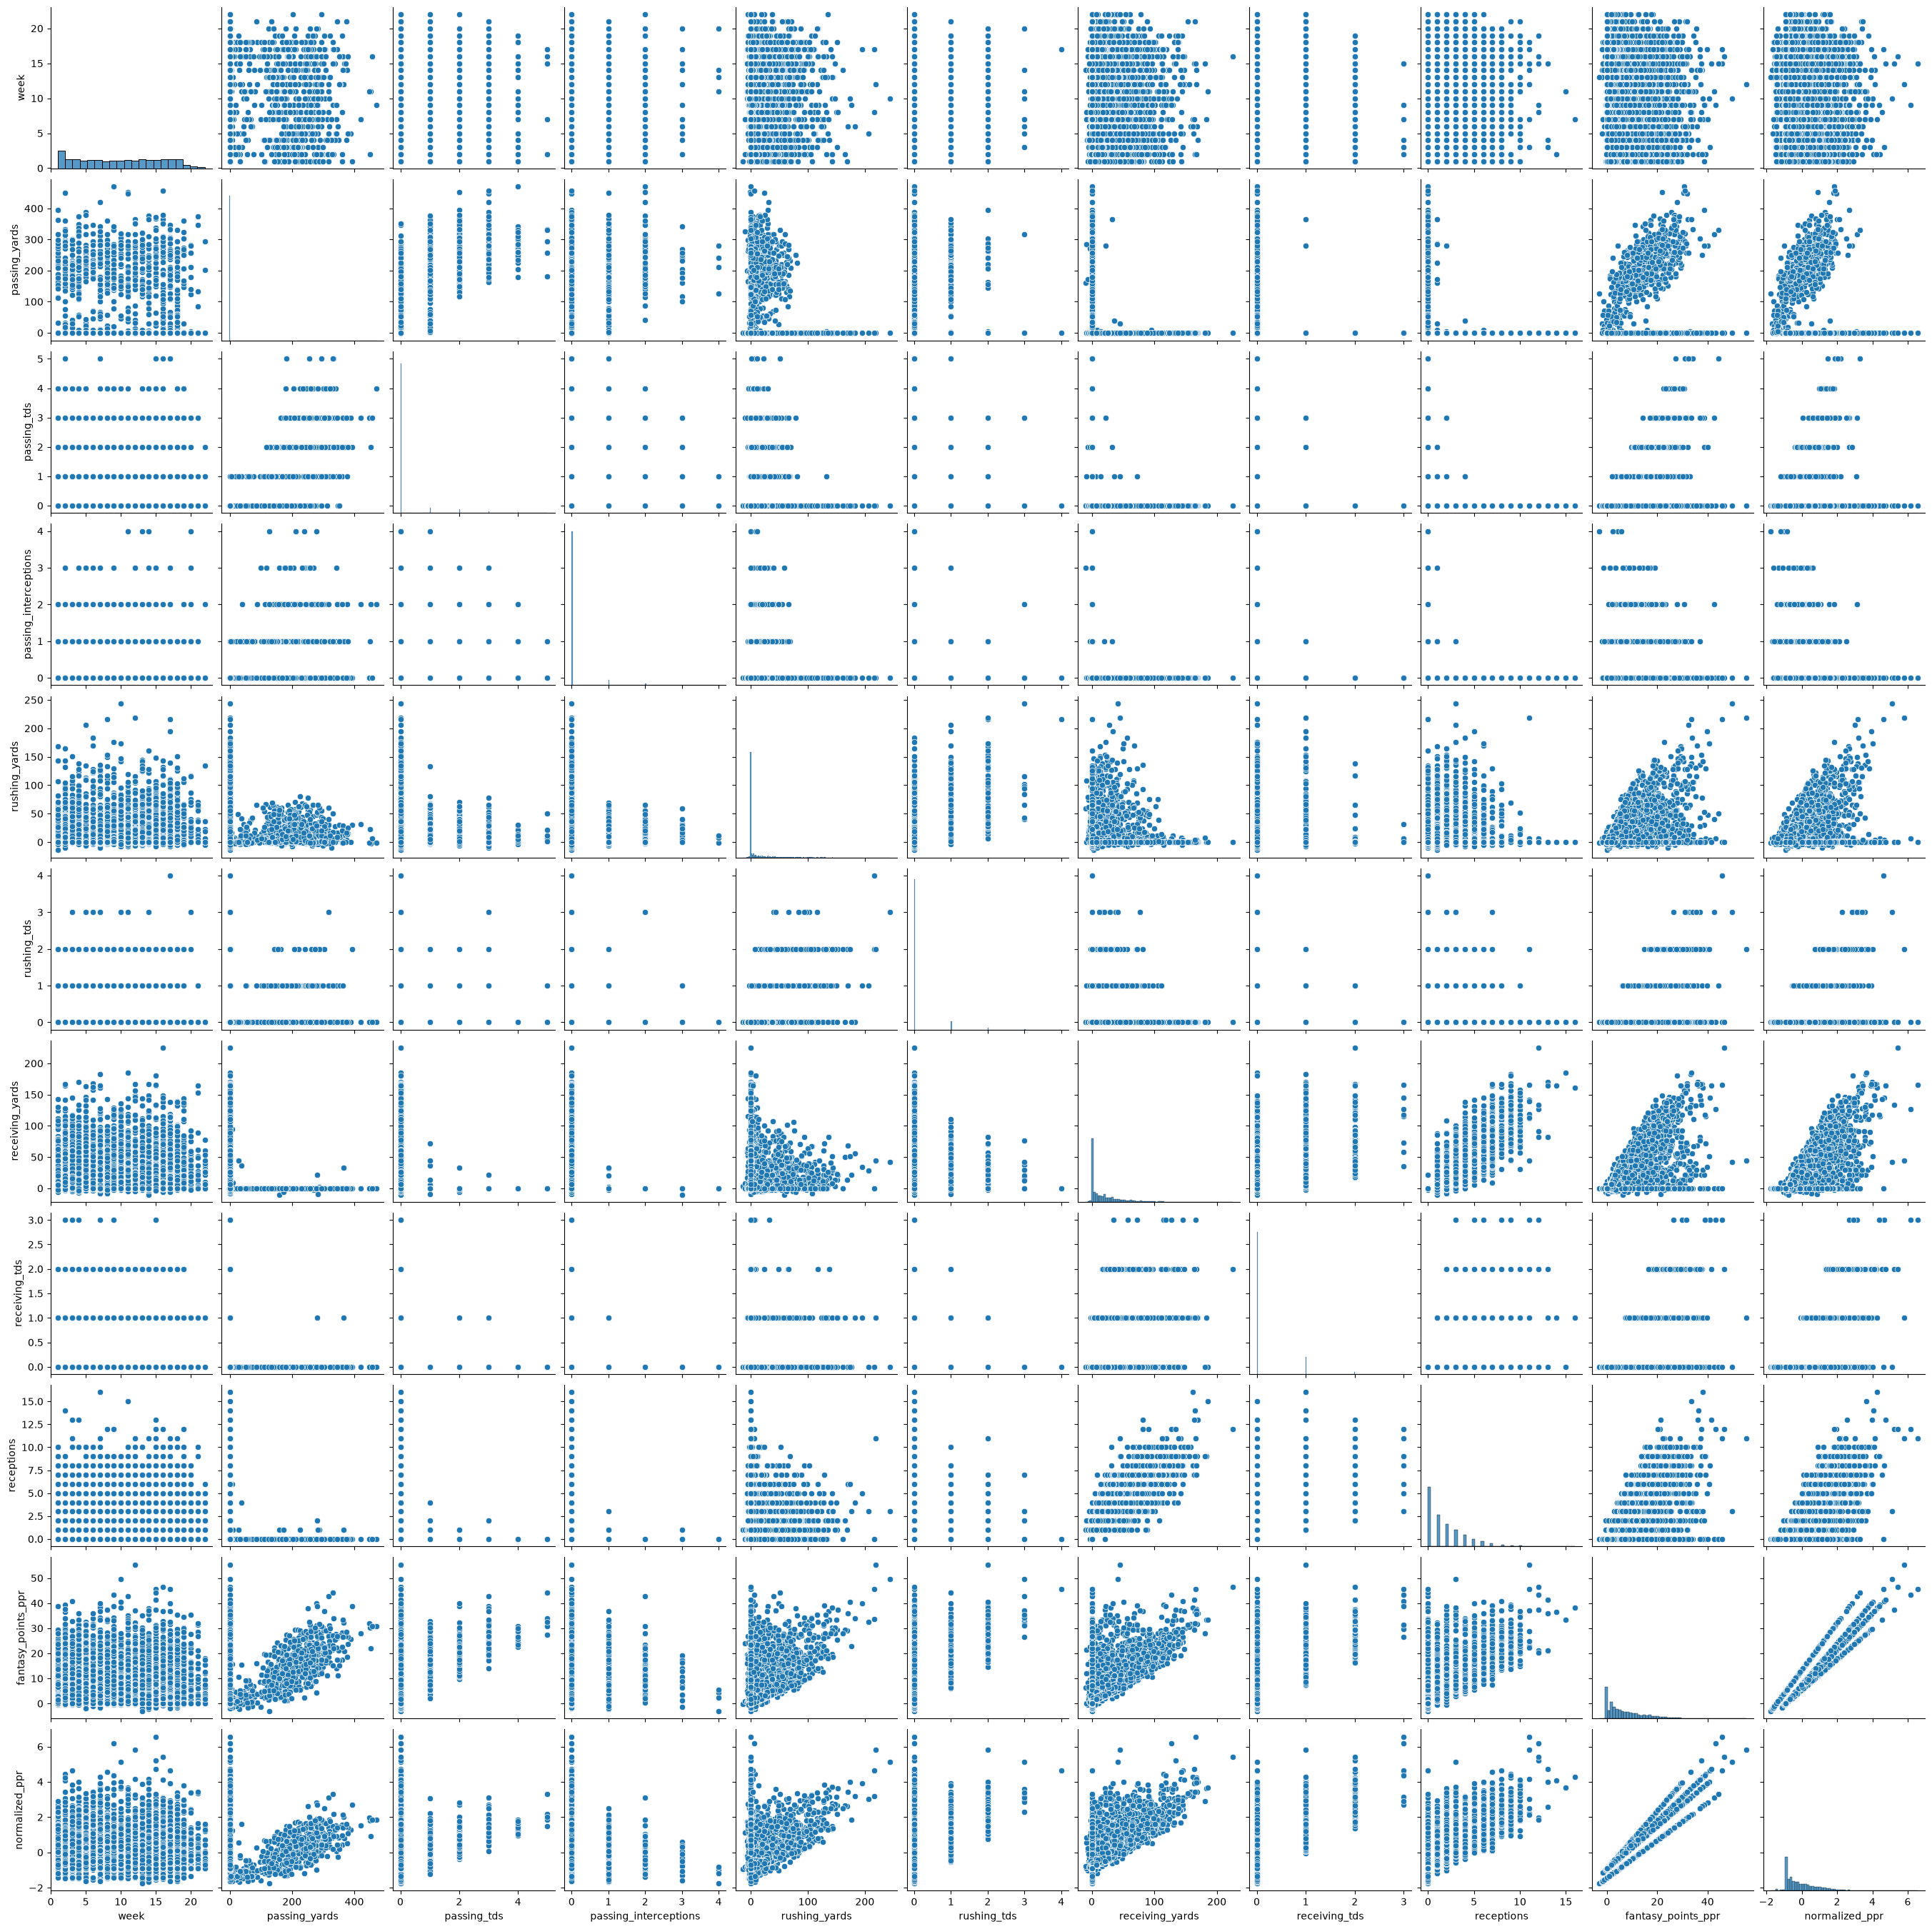

In [90]:
import seaborn as sns

fantasy_data = filtered_df.copy()

sns.pairplot(fantasy_data)

While this is really cool, it's probably too much information to include as a panel on my dashboard. I'll restrict the columns to only be those I really care about and their interactions with overall points.

One additional note on the plot, was confused as to what the distinct four diagonal lines were on the standard vs. normalized points. After inspecting realized it was the four different positions, which is a neat way to vizual how that data transformation worked.

Text(0.5, 1.1, 'Individual Statistics Affects on Fantasy Points')

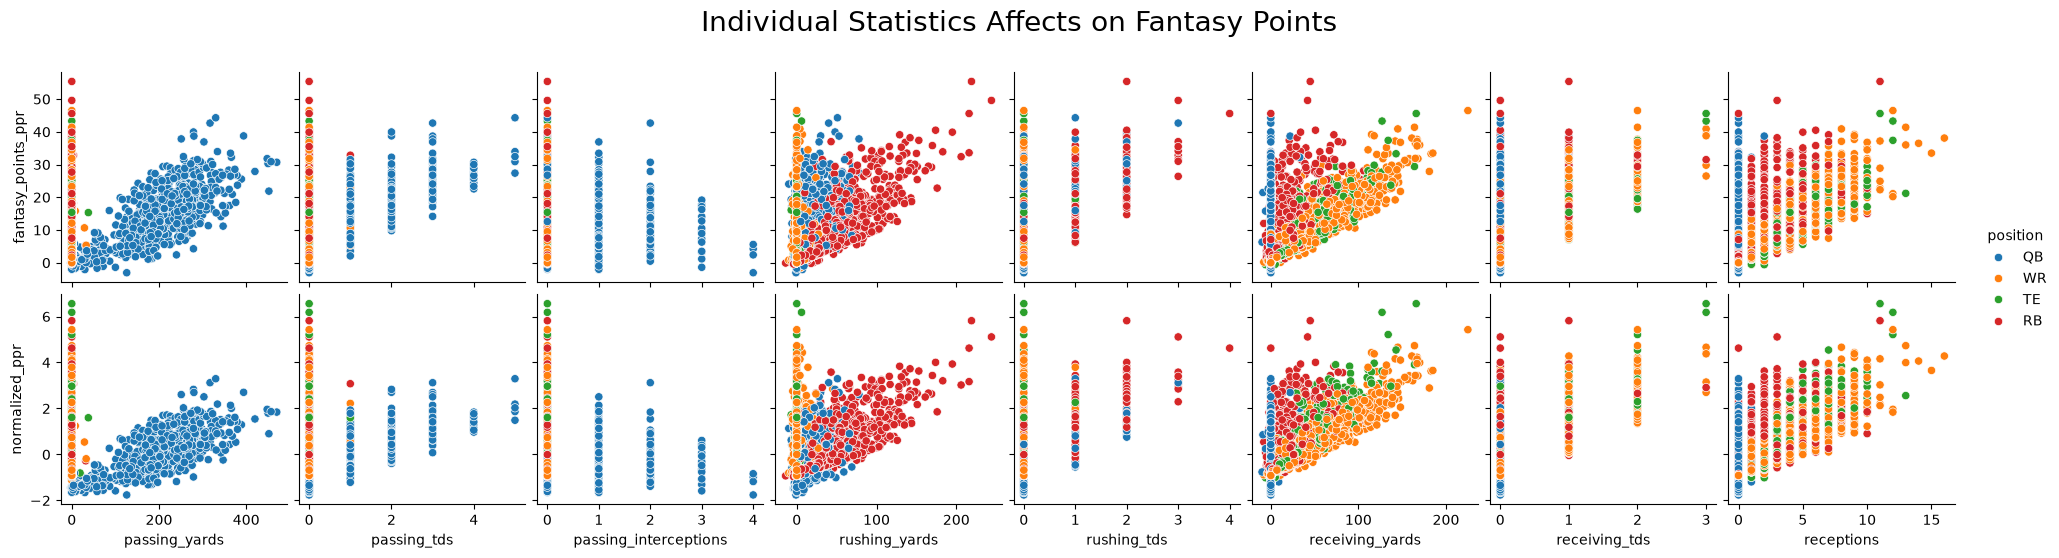

In [73]:
fantasy_data = filtered_df.copy()

matrices = sns.pairplot(data=fantasy_data,
             x_vars=['passing_yards', 'passing_tds', 'passing_interceptions',
                     'rushing_yards', 'rushing_tds', 'receiving_yards',	
                     'receiving_tds', 'receptions'],
            y_vars=['fantasy_points_ppr', 'normalized_ppr'],
            hue='position'
            )
matrices.figure.suptitle("Individual Statistics Affects on Fantasy Points", y = 1.1, fontsize = 20)

There are several interesting takeaways from this plot.
1. Quarterbacks don't seem to thrive when throwing no interceptions. A little risk appears to be good for the position from a scoring perspective.
2. Tightends appear to be heavily reliant on touchdowns, as the top relative performances appear to come from multiple touchdown games at a higher rate than other positions.
3. Wide recievers seem to be much less dependent on touchdowns than other positions.

### Time Series

I want to see if certian positions get better as the season goes along, and if the region and weather of these teams affects this. To do this I'm going to create a time series of average raw points over time. Because this is an overall average, I won't need the normalized data for this plot.

<Axes: xlabel='week', ylabel='fantasy_points_ppr'>

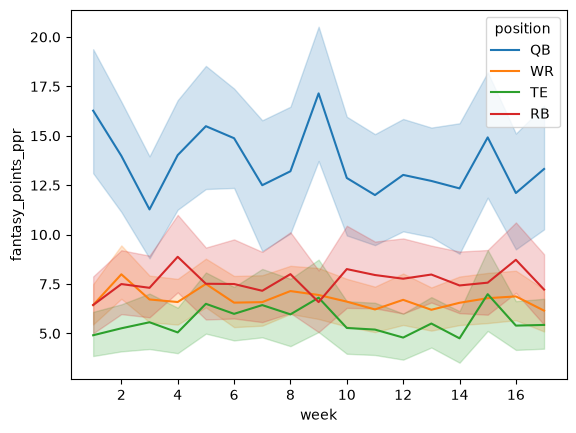

In [109]:
fantasy_data = filtered_df.copy()

sns.lineplot(data=fantasy_data,
             x='week',
             y='fantasy_points_ppr',
             hue='position')

My theory doesn't look correct so far. We'll have to see if toggling the divisions as a reactive value adds any additional insight into this data. I'll supplement this after adding that functionality.

### TreeMap

I've investigated some overall trends that I think are interesting, but I really haven't answered the main question of this excercise. **WHO DO I DRAFT NEXT YEAR????**

To answer this, I want to add all players in a overall chart. My inspiration for this map are the famous S&P 500 treemaps that show stock performance by sector. I've linked an example below.

https://public.tableau.com/app/profile/dorian.barosan/viz/StockMarketOverview-NestedTreemap/StockMarketTreemap

In this example player position will be my sector, with total fantasy points controlling the size of the square. I'll start by including all players, but I may have to limit this to just the top portion if the squares get unreadable.

In [108]:
%pip install plotly


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [136]:
import plotly.express as px

fantasy_data = filtered_df.copy()

position_color_map = {"(?)": "lightgrey", "RB": '#d62728', 'QB': '#1f77b4', 'WR': '#ff7f0e', 'TE': '#2ca02c'}

season_data = (
    fantasy_data.groupby(['position', 'player_id', 'player_name'], as_index=False)
    .agg(
        normalized_ppr=('normalized_ppr', 'sum'),
        fantasy_points_ppr=('fantasy_points_ppr', 'sum')
    )
)

season_data = season_data[season_data['normalized_ppr'] > 0]

fig = px.treemap(
    season_data,
    path=[px.Constant('Total Points 2025 (normalized)'), 'position', 'player_name'], 
    values='normalized_ppr',
    color='position', 
    color_discrete_map=position_color_map,                                    
    color_discrete_sequence=px.colors.qualitative.Set2,   
    title='Total 2025 Season Points',
    hover_name = 'player_name',
    hover_data = ['fantasy_points_ppr']
)

fig.update_traces(
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Raw Points: %{customdata[0]:.1f}<br>'
        'Normalized Points: %{value:.1f}<br>'
    ),
    root_color="lightgrey",
    insidetextfont=dict(color="white"),
    marker=dict(line=dict(width=2, color="grey"))
)

fig.show()

This is an awesome overall chart, a couple takeaways I have from this.
1. The theme of demphasizing quarterbacks continues, Josh Allen appears barely more impactful then the rest of the top 10 quarterbacks. This is particularly insightful as most leagues only have 10 teams, so there should be little scarcity to aquire a similar quarterback.
2. Trey Mcbride appears to be widely impactful compared to his position in a way no other player is. I will definetly be targetting him next season.
3. Runningback appears to be less deep than wide reciver, the boxes quickly shrink in impact as wide reciver tapers off more gradually.
4. I know from experience that wide recievers get hurt less frequently than runningbacks. Due to this, and their comporable relative values, I will be targeting this position heavily next year.

**Note:** AI was used in the generation of this plot. Prompts have been included in the AI log.

Now that I have my vizualizations, I can add them into an interactive dashboard.

## Dashboard

I was really impressed by the lecture on Panel dashboards. I would like to explore using this package for combining these vizualations into one hosted site.

In [137]:
%pwd

'/Users/caseydinan/Documents/SAIDS_521'